In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
project_root = Path.cwd().parent.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import src.mapping_migrations as mm

In [ ]:
data_dir = project_root / "data/"
outputs_dir = project_root / "outputs/"
database_path = data_dir / "all_hiski_records.sqlite3"
migration_jsonl_dir = outputs_dir / "json/migration_jsonls/2-final"

FUZZY_SCORE_CUTOFF = 85
MIGRATION_KIND = "emigration"

toponyms_with_coordinates = mm.load_toponym_lookup(
    outputs_dir / "json/db_toponyms_with_coordinates_extended.json"
)
parish_records = mm.load_parish_records(database_path)

## Load events

In [20]:
migration_events, skip_counts = mm.load_migration_events(migration_jsonl_dir)
print(pd.Series(skip_counts).to_string())
print(len(migration_events), "usable events")

468 jsonl files


  0%|          | 0/468 [00:00<?, ?it/s]

rows_read                           6723143
counterpart: only_own_place_role    2617175
skipped: no related toponyms         626767
skipped: no information              760469
skipped: duplicate                   620533
counterpart: explicit_role          1150776
skipped: unknown in/out              923534
counterpart: single_place             23889
1092875 usable events


In [21]:
emigrated_records, immigrated_records = mm.split_by_direction(migration_events)

unknown_parish_ids = set(migration_events["parish_id"].dropna().astype(int)) - set(
    parish_records["id"]
)
print(len(unknown_parish_ids), "parish ids in the jsonl files are not in the parish table")
print(
    "year missing or non-numeric:", migration_events["year"].isna().sum(),
    "of", len(migration_events)
)

20 parish ids in the jsonl files are not in the parish table
year missing or non-numeric: 0 of 1092875


## Resolve toponyms and coordinates

In [6]:
emigrations_with_counterpart = mm.attach_counterpart_toponyms(
    emigrated_records,
    "destination",
    toponyms_with_coordinates,
    score_cutoff=FUZZY_SCORE_CUTOFF,
)
immigrations_with_counterpart = mm.attach_counterpart_toponyms(
    immigrated_records,
    "source",
    toponyms_with_coordinates,
    score_cutoff=FUZZY_SCORE_CUTOFF,
)

parish_coordinates = mm.build_parish_coordinates(
    parish_records, toponyms_with_coordinates
)
parish_names_not_in_dict = parish_coordinates.loc[
    ~parish_coordinates["parish_name"]
    .str.strip()
    .isin(toponyms_with_coordinates),
    "parish_name",
]
print(
    f"{len(parish_names_not_in_dict)} of {len(parish_coordinates)}",
    "parish names are not in the toponym dict",
)

  0%|          | 0/123881 [00:00<?, ?it/s]

  0%|          | 0/156413 [00:00<?, ?it/s]

1 of 522 parish names are not in the toponym dict


In [7]:
emigrations_located = mm.attach_coordinates(emigrations_with_counterpart, parish_coordinates)
immigrations_located = mm.attach_coordinates(immigrations_with_counterpart, parish_coordinates)

plottable_emigrations = mm.drop_records_missing_coordinates(emigrations_located)
plottable_immigrations = mm.drop_records_missing_coordinates(immigrations_located)
print(len(plottable_emigrations), "emigration rows and",
      len(plottable_immigrations), "immigration rows can be plotted")

194182 emigration rows and 305132 immigration rows can be plotted


In [8]:
migrations = mm.build_migrations(plottable_emigrations, plottable_immigrations)
print(migrations["kind"].value_counts().to_string())

kind
immigration    305132
emigration     194182


## Static map

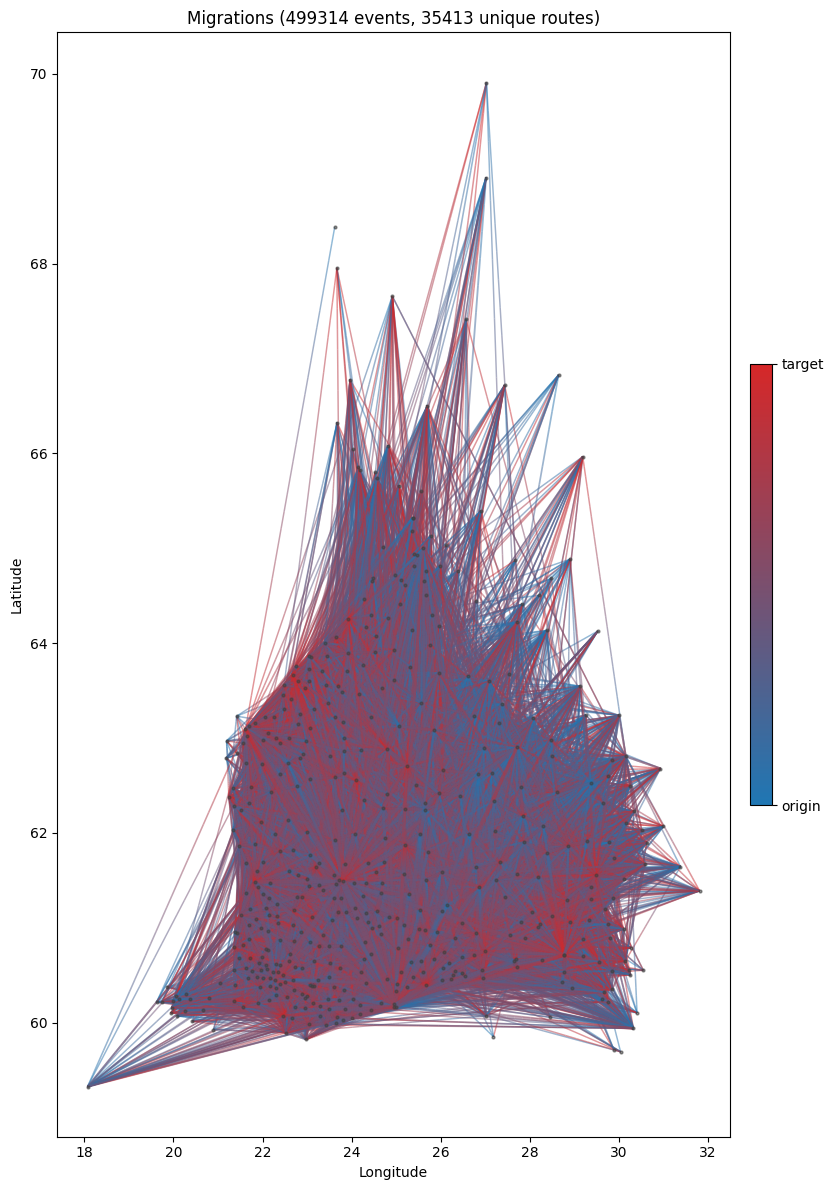

In [9]:
figure, map_axes, unique_routes = mm.draw_static_migration_map(migrations)
plt.show()

## Interactive map

In [ ]:
plot_events = mm.prepare_plot_events(migrations, MIGRATION_KIND)
yearly_routes = mm.build_yearly_routes(plot_events)
years = sorted(yearly_routes[mm.YEAR_BIN_COLUMN].unique())
print(f"{len(yearly_routes)} year-routes over {len(years)} years ({years[0]}-{years[-1]})")

31542 year-routes over 21 years (1820-1920)


In [ ]:
migration_figure = mm.build_migration_figure(
    yearly_routes,
    MIGRATION_KIND,
    source_description="OCR data"
)
migration_figure.show()

In [12]:
Path("migrations_ocr.html").write_text(migration_figure.to_html())

29481254

## Metrics

### General

In [13]:
display("emigrated (destination)", mm.summarize_toponym_coverage(emigrations_located))
display("immigrated (source)", mm.summarize_toponym_coverage(immigrations_located))

'emigrated (destination)'

,count
rows,434353
empty place name,0
exact match,152430
fuzzy match,68943
no match,212980
"matched, but no coordinates",7415
"matched, with coordinates",213958


'immigrated (source)'

,count
rows,658522
empty place name,0
exact match,262262
fuzzy match,98253
no match,298007
"matched, but no coordinates",11615
"matched, with coordinates",348900


### Distances

Typical distances moved

In [14]:
migrations["distance"] = mm.compute_distances_in_metres(migrations)
print(
    "mean:", round(migrations["distance"].mean() / 1000), "km\n"
    "median:", round(migrations["distance"].median() / 1000), "km\n"
    "mode:", round(migrations["distance"].mode()[0] / 1000), "km"
)

mean: 82 km
median: 40 km
mode: 45 km


In [15]:
unique_migrations = (
    migrations[["kind", "origin_name", "target_name", "distance"]]
    .drop_duplicates()
    .sort_values(by="distance", ascending=False)
)
unique_migrations

,kind,origin_name,target_name,distance
185698,emigration,Helsinki,Utsjoki,1.090226e+06
406473,immigration,Utsjoki,Somero,1.047091e+06
478945,immigration,Utsjoki,Virolahti,1.040187e+06
254451,immigration,Inari,Bromarv,1.011873e+06
31999,emigration,Bromarv,Inari,1.011873e+06
...,...,...,...,...
406478,immigration,Somero,Somero,0.000000e+00
407999,immigration,Sulkava,Sulkava,0.000000e+00
403270,immigration,Sippola,Sippola,0.000000e+00
59818,emigration,Eno,Eno,0.000000e+00


### Most frequent toponyms

In [16]:
print(migrations["origin_name"].value_counts().head(10).to_string())

origin_name
Helsinki                         31715
Tampere                          22501
Orimattila                        9487
Porvoo                            8507
Turku                             7407
Nastola                           6905
Elimäki                           6033
Jyväskylän kaupunkiseurakunta     5821
Tuusula                           5754
Pirkkala                          5589


In [17]:
print(migrations["target_name"].value_counts().head(10).to_string())

target_name
Tampere       35237
Helsinki      26368
Porvoo        24948
Orimattila    10729
Pori          10274
Viipuri        7600
Hollola        6931
Kymi           6450
Jämsä          6365
Tuusula        5780


### Most common fuzzy matches

In [18]:
print(mm.count_fuzzy_matches(emigrations_located).head(25).to_string())

counterpart_raw_name  counterpart_matched_key  counterpart_normalized_name  counterpart_match_score
Helinki               Helsinki                 Helsinki                     93.333333                  930
H:fors.               H:fors                   Helsinki                     92.307692                  680
Tampere.              Tampere                  Tampere                      93.333333                  506
Helsinki.             Helsinki                 Helsinki                     94.117647                  505
Hollolan              Hollolaan                Hollola                      94.117647                  366
Helsinge.             Helsinge                 Helsingin pitäjä             94.117647                  322
Hollala               Hollola                  Hollola                      85.714286                  322
Hellinki              Helsinki                 Helsinki                     87.500000                  313
Ulvilaan              Ulvila                

### Most frequent names not found

In [19]:
for located_records, place_label in [
    (emigrations_located, "destination"),
    (immigrations_located, "source"),
]:
    unmatched_name_counts = mm.count_unmatched_names(located_records)
    print(f"\nTop unmatched {place_label} values:")
    print(unmatched_name_counts.head(10).to_string())
    print("total unmatched:", unmatched_name_counts.sum())


Top unmatched destination values:
counterpart_raw_name
Siirto             521
"                  482
""                 451
Toivakka           435
SiirtoTransport    416
1                  405
5.                 404
Pernä              346
sn                 340
Kotkaan            337
total unmatched: 212980

Top unmatched source values:
counterpart_raw_name
1           1490
"            706
Pernä        641
Pari         506
-            476
Marras       456
2            455
1.           444
3            433
Vilppula     424
total unmatched: 298007
